# AI-Assisted Decision-Support Framework for Disaster Relief Resource Allocation Under Uncertainty

This notebook reproduces the reported tables and figures from pinned experiment outputs. Run from the repository root or from the research directory. The technical guide provides commands for reconstructing original predictions, re-reading raster windows, rebuilding features and fitting new models. Historical obligations, physical observations, model estimates and simulated humanitarian need are separate data layers.

In [1]:
from pathlib import Path
from hashlib import sha256
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

study = Path("research") if Path("research/results").exists() else Path(".")
repo = study.resolve().parent
results = study / "results"
figures = study / "figures"
figures.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "savefig.bbox": "tight"})
blue, orange, green, slate = "#1f5a91", "#b35322", "#19705f", "#4c6170"

def load(name):
    return pd.read_csv(results / name)

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(figures / f"{name}.png", dpi=180)
    plt.show()
    plt.close(fig)

for entry in (study / "inputs/SHA256SUMS").read_text().splitlines():
    expected, relative = entry.split("  ", 1)
    assert sha256((repo / relative).read_bytes()).hexdigest() == expected, relative
print("Frozen workbook, retained archive and source-manifest hashes verified.")

Frozen workbook, retained archive and source-manifest hashes verified.


## 1. Frozen historical benchmark

The workbook contains 971 unique records from FY2010–24. The original historical target is nonnegative FEMA mission-assignment obligations in USD. Its six funding bands are left-closed at 0, 100,000, 1 million, 50 million, 200 million and 500 million. The frozen router used a leave-fiscal-year-out experiment that could use later years in training. Its target and protocol remain frozen.

In [2]:
cohort = load("hazards/cohort_features.csv")
frozen = load("track_a/all_912_immutable_overlay.csv")
assert len(cohort) == 971 and cohort.disasterNumber.is_unique
assert len(frozen) == 912 and frozen.actual_band.eq(frozen.router_pred).sum() == 830
amount = frozen.challenger_stack_prediction
assert np.isclose((amount-frozen.target).abs().mean(), 5014819.011614494)
display(load("track_a/model_metrics.csv").query("axis == 'all'")[
    ["variant","n","accuracy","balanced_accuracy","macro_f1","mae_usd","rmse_usd","r2"]].round(4))

,variant,n,accuracy,balanced_accuracy,macro_f1,mae_usd,rmse_usd,r2
0,track_a_original_stack,912,0.9101,0.8955,0.8786,5.131360e+06,6.471480e+07,0.8866
35,track_a_reported_historical_50_200m_overlay,912,0.9101,0.8955,0.8786,5.014819e+06,6.465375e+07,0.8868
70,track_a_two_accepted_low_specialists,912,0.9101,0.8955,0.8786,5.127644e+06,6.471478e+07,0.8866


## 2. Flood investigations and observability

Each window compares the preceding month with the incident-start month and the corresponding prior-year months. Only dry-to-water and water-to-dry transitions count. The common observation mask contains valid classifications on every required date. The minimum common threshold is 30% of window cells. Report gains and losses per 100 observable km² and subtract placebo net change from event net change. The annual placebo gives evidence about seasonality and cannot certify absence of flooding.

,threshold_percent,sites,disasters,event_gain_rate,event_loss_rate,placebo_gain_rate,placebo_loss_rate,delta_net_rate,median_case_delta
18,30,44,27,0.0809,0.1911,0.0278,0.0809,-0.0571,0.0
21,60,40,27,0.0835,0.1641,0.0287,0.0740,-0.0353,0.0
24,80,36,25,0.0872,0.1769,0.0309,0.0795,-0.0411,0.0


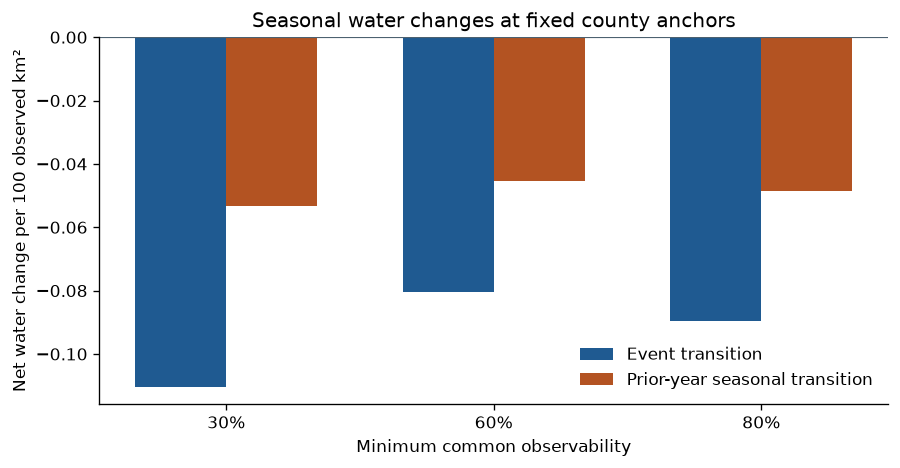

In [3]:
p50 = load("phase50/phase50_summary.csv")
replay = load("phase50/phase50_phase49_replay.csv")
months = load("phase50/phase50_monthly_source_log.csv")
assert replay.status.eq("exact_match").sum() == 67
assert months.status.eq("read_ok").sum() == 289
seasonal = p50.query("design == 'seasonal' and denominator == 'common' and population == 'anchors'")
display(seasonal[["threshold_percent","sites","disasters","event_gain_rate","event_loss_rate",
                  "placebo_gain_rate","placebo_loss_rate","delta_net_rate","median_case_delta"]].round(4))
fig, ax = plt.subplots(figsize=(7.6, 4))
x = np.arange(len(seasonal))
ax.bar(x-.17, seasonal.event_net_rate, width=.34, color=blue, label="Event transition")
ax.bar(x+.17, seasonal.placebo_net_rate, width=.34, color=orange, label="Prior-year seasonal transition")
ax.set(xticks=x, xticklabels=[f"{n}%" for n in seasonal.threshold_percent],
       xlabel="Minimum common observability", ylabel="Net water change per 100 observed km²",
       title="Seasonal water changes at fixed county anchors")
ax.axhline(0, color=slate, linewidth=.7)
ax.legend(frameon=False)
finish(fig, "phase50_seasonal_water")

### Independent evidence in Minnesota

The two Houston County windows with the strongest Landsat water gains had overlap with flood-colored cells in NASA's independent three-day MODIS rendering. The relatively coarse render and the incomplete coverage limit this to local overlap. Transparent cells have ambiguous dry and missing states. Record dates precede, span and follow the April 11 incident start. The USGS gauge series test regional hydrologic context only.

,date,sample_id,jrc_gain_centers,gaining_centers_with_tile,gaining_centers_in_rendered_flood_cell
0,2023-04-10,4722_27055_2,5407,5407,2473
1,2023-04-20,4722_27055_2,5407,5407,896
2,2023-04-25,4722_27055_2,5407,5407,462
3,2024-04-25,4722_27055_2,5407,5407,225
4,2023-04-10,4722_27055_3,2288,2288,1170
5,2023-04-20,4722_27055_3,2288,2288,1279
6,2023-04-25,4722_27055_3,2288,2288,25


,station_name,year,time,value,unit_of_measure
1,Mississippi River at Aitkin,2022,2022-04-30,8400,ft^3/s
3,Mississippi River at Aitkin,2023,2023-04-25,14100,ft^3/s
5,Mississippi River at Aitkin,2024,2024-04-30,4320,ft^3/s
7,Root River near Houston,2022,2022-04-14,4420,ft^3/s
9,Root River near Houston,2023,2023-04-02,4160,ft^3/s
11,Root River near Houston,2024,2024-04-20,940,ft^3/s


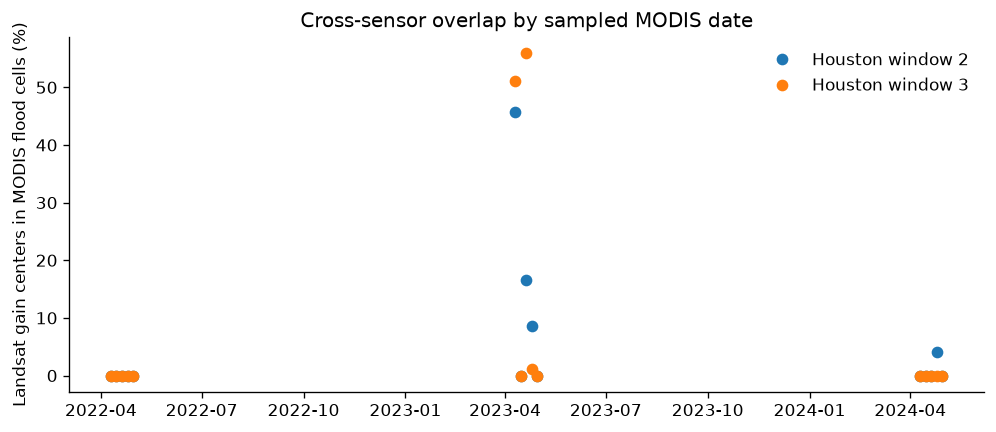

In [4]:
overlay = load("phase51/dr4722_modis_jrc_overlay.csv")
display(overlay.query("gaining_centers_in_rendered_flood_cell > 0").reset_index(drop=True))
gauge = load("phase51/dr4722_gauge_monthly_peaks.csv")
display(gauge.query("month == 4")[["station_name","year","time","value","unit_of_measure"]])
zoom = overlay[overlay.sample_id.isin(["4722_27055_2","4722_27055_3"])].copy()
zoom["overlap_fraction"] = zoom.gaining_centers_in_rendered_flood_cell / zoom.jrc_gain_centers
fig, ax = plt.subplots(figsize=(8.4, 3.7))
for name, group in zoom.groupby("sample_id"):
    ax.plot(pd.to_datetime(group.date), 100*group.overlap_fraction, "o", label=f"Houston window {name[-1]}")
ax.set(ylabel="Landsat gain centers in MODIS flood cells (%)",
       title="Cross-sensor overlap by sampled MODIS date")
ax.legend(frameon=False)
finish(fig, "dr4722_sensor_overlap")

## 3. Multi-hazard measurements and coverage

Make the county/date/event linkage explicit and retain the source identifiers. Hurricane estimates use track-date and location matching with post-event best tracks. MTBS named assignments require perimeter intersection. NOAA county records and ComCat links are candidate associations. NASA Daymet values are gridded estimates. The population column describes total designated-county population. Missing values remain missing until training-only preprocessing.

,incidentType,total,designated_2020_population,noaa_event_count,measured_gust_kt,tornado_ef,cyclone_max_wind_kt,mtbs_burned_acres,quake_magnitude,daymet_point_max_24h_mm
0,Severe Storm,430,369,301,123,155,0,0,0,0
1,Flood,198,167,157,0,0,0,0,0,87
2,Hurricane,108,83,67,0,0,86,0,0,0
3,Biological,59,44,0,0,0,0,0,0,0
4,Snowstorm,36,34,0,0,0,0,0,0,0
5,Fire,33,28,0,0,0,0,4,0,0
6,Tornado,27,25,25,0,25,0,0,0,0
7,Severe Ice Storm,21,21,0,0,0,0,0,0,0
8,Winter Storm,11,7,0,0,0,0,0,0,0
9,Mud/Landslide,9,4,1,0,0,0,0,0,0


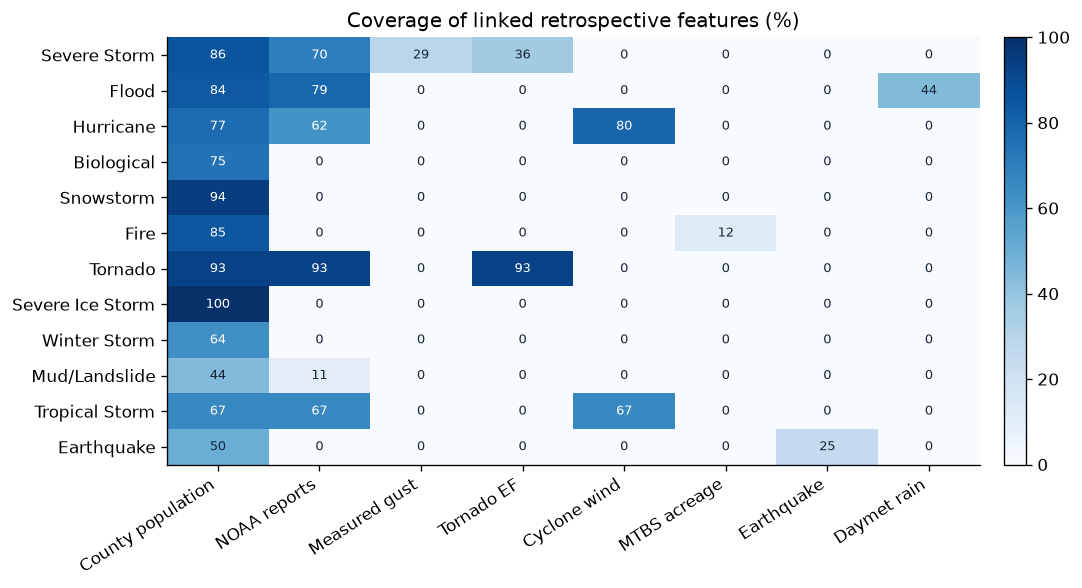

In [5]:
coverage = load("hazards/hazard_coverage.csv")
cols = ["designated_2020_population","noaa_event_count","measured_gust_kt","tornado_ef",
        "cyclone_max_wind_kt","mtbs_burned_acres","quake_magnitude","daymet_point_max_24h_mm"]
short = ["County population","NOAA reports","Measured gust","Tornado EF",
         "Cyclone wind","MTBS acreage","Earthquake","Daymet rain"]
show = coverage.query("total >= 8").sort_values("total", ascending=False).copy()
display(show[["incidentType","total",*cols]].reset_index(drop=True))
pct = show[cols].div(show.total, axis=0).to_numpy() * 100
fig, ax = plt.subplots(figsize=(9.8, 5))
im = ax.imshow(pct, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_yticks(np.arange(len(show)), show.incidentType)
ax.set_xticks(np.arange(len(short)), short, rotation=33, ha="right")
for i, row in enumerate(pct):
    for j, v in enumerate(row):
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 53 else "#172638", fontsize=8)
ax.set_title("Coverage of linked retrospective features (%)")
fig.colorbar(im, ax=ax, pad=.025)
finish(fig, "hazard_feature_coverage")

## 4. Forward validation and funding estimates

For each held year, take strictly earlier fiscal years and remove training events whose dates intersect the earliest held-out incident and groups shared with the test cases. Within the training data, select classifier hyperparameters by six-class macro F1 and amount hyperparameters by mean absolute dollar error on two earlier chronological origins. All variants score the same 376 cases. Historical calendar sources can be revised after the disaster.

,test_year,n_train,n_test,max_train_fy,max_train_end,min_test_incident_start,rejected_earlier_records,inner_years,linear_probability_weight,linear_amount_weight
0,2019,514,68,2018,2018-04-20,2018-05-01,22,"2017,2018",0.50,1
1,2020,593,43,2019,2019-06-25,2019-06-30,11,"2018,2019",0.25,1
2,2021,638,57,2020,2020-05-22,2020-06-29,9,"2019,2020",0.25,1
3,2022,692,52,2021,2021-07-10,2021-07-12,12,"2020,2021",0.25,0
4,2023,746,68,2022,2022-07-05,2022-07-12,10,"2021,2022",0.25,0
5,2024,796,88,2023,2023-04-30,2023-05-01,28,"2022,2023",0.00,0


,variant,accuracy,balanced_accuracy,macro_f1,mae_usd,r2
0,ablation_combined,0.59309,0.32088,0.27781,1.990280e+07,-0.01088
23,ablation_geography,0.57979,0.30150,0.26680,1.989300e+07,-0.01022
46,ablation_geography_physical,0.58245,0.33043,0.27750,1.990318e+07,-0.01093
69,ablation_metadata,0.46011,0.40749,0.22370,1.986446e+07,-0.00906
92,ablation_physical,0.48936,0.26502,0.22604,1.987878e+07,-0.01064
115,ablation_report_proxy,0.56117,0.29111,0.25435,1.992176e+07,-0.00933
138,ablation_retrospective_metadata,0.51064,0.42524,0.24315,1.989201e+07,-0.00986
161,ablation_verified_link_only,0.59574,0.33191,0.28435,1.990514e+07,-0.01088
184,equal_blend_verified,0.60106,0.30323,0.28061,3.128839e+07,-0.66691
207,hard_funding_band,0.59574,0.33191,0.28435,8.085428e+07,-3.83792


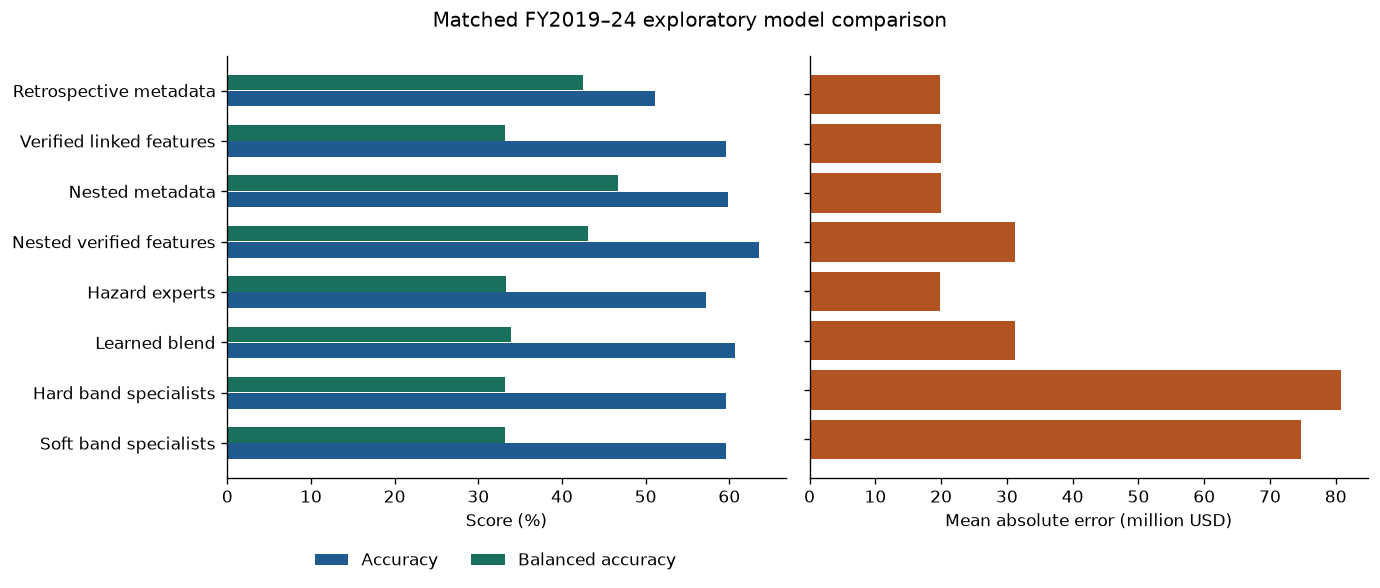

In [6]:
fold = load("forward/forward_fold_audit.csv")
p = load("forward/forward_predictions.csv")
assert (fold.max_train_fy < fold.test_year).all()
assert (pd.to_datetime(fold.max_train_end) < pd.to_datetime(fold.min_test_incident_start)).all()
assert p.groupby("variant").size().eq(376).all()
assert np.allclose(p[[f"p_band_{i}" for i in range(6)]].sum(axis=1), 1)
metrics = load("forward/model_metrics.csv").query("axis == 'all'").copy()
display(fold)
display(metrics[["variant","accuracy","balanced_accuracy","macro_f1","mae_usd","r2"]].round(5))
order = ["ablation_retrospective_metadata","ablation_verified_link_only","nested_metadata","nested_verified_link_only",
         "hazard_experts_verified","oof_weighted_blend_verified","hard_funding_band","soft_funding_band"]
labels = ["Retrospective metadata", "Verified linked features", "Nested metadata", "Nested verified features",
          "Hazard experts", "Learned blend", "Hard band specialists", "Soft band specialists"]
m = metrics.set_index("variant").loc[order]
fig, axs = plt.subplots(1, 2, figsize=(11.6, 5))
y = np.arange(len(order))
axs[0].barh(y+.16, 100*m.accuracy, height=.31, color=blue, label="Accuracy")
axs[0].barh(y-.16, 100*m.balanced_accuracy, height=.31, color=green, label="Balanced accuracy")
axs[0].set(yticks=y, yticklabels=labels, xlabel="Score (%)")
axs[0].invert_yaxis()
axs[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(.48, -.14), ncol=2)
axs[1].barh(y, m.mae_usd/1e6, color=orange)
axs[1].set(yticks=y, yticklabels=[], xlabel="Mean absolute error (million USD)")
axs[1].invert_yaxis()
fig.suptitle("Matched FY2019–24 exploratory model comparison")
finish(fig, "matched_forward_comparison")

### Grouped interpretation and a prospective cohort

The differences between fixed Extra Trees ablations quantify the incremental contribution of a feature family under this procedure. These changes cannot establish causal effects. The 143-case FY2025 roster was collected without outcome dollars. Authentic contemporaneous sources and mature comparable outcomes are required for a new independent test.

In [7]:
deltas = load("forward/paired_event_bootstrap.csv")
display(deltas[deltas.variant.str.startswith("ablation")][
    ["variant","accuracy_difference","accuracy_ci_low","accuracy_ci_high","mae_difference_usd","mae_ci_low","mae_ci_high"]].round(4))
new_ids = load("follow_up/fy2025_target_free_roster.csv")
assert len(new_ids) == 143 and not new_ids.disasterNumber.isin(cohort.disasterNumber).any()
display(new_ids.groupby("incidentType").size().sort_values(ascending=False).rename("reserved declarations").to_frame())

,variant,accuracy_difference,accuracy_ci_low,accuracy_ci_high,mae_difference_usd,mae_ci_low,mae_ci_high
0,ablation_combined,0.0824,0.0323,0.1362,10792.2458,-18704.7460,45393.6050
1,ablation_geography,0.0691,0.0277,0.1157,987.2165,-29193.0486,28411.6513
2,ablation_geography_physical,0.0718,0.0242,0.1206,11170.9042,-17752.8663,43135.8703
3,ablation_metadata,-0.0505,-0.0844,-0.0174,-27548.8205,-52010.9241,-6729.2407
4,ablation_physical,-0.0213,-0.0610,0.0191,-13232.3555,-63362.7405,22013.6101
5,ablation_report_proxy,0.0505,0.0026,0.0975,29752.5887,-22327.7875,94621.3749
6,ablation_retrospective_metadata,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,ablation_verified_link_only,0.0851,0.0384,0.1294,13131.1234,-14818.4044,45128.6843


,reserved declarations
incidentType,
Fire,82
Severe Storm,31
Flood,14
Tropical Storm,7
Hurricane,4
Winter Storm,2
Mud/Landslide,1
Severe Ice Storm,1
Tropical Depression,1


## 5. Prediction intervals and decline-to-automate decisions

The dollar and log1p methods calibrate residuals on earlier forward predictions. The conformal correction selects the order statistic at ceiling((n+1) × level), and the inverse transformation gives a USD interval. Chronological shift and very small upper bands limit coverage claims. A reviewer examines interval width, missing evidence, high band and low router probability separately.

,method,level,n,coverage,median_width_usd,mean_width_usd,review_rate
8,dollar,0.8,308,0.844156,7.485873e+05,8.663405e+05,0.516234
9,dollar,0.9,308,0.912338,4.283241e+06,4.004413e+06,0.516234
10,log1p,0.8,308,0.827922,1.598723e+05,2.471733e+09,0.542208
11,log1p,0.9,308,0.922078,8.980126e+05,1.200009e+10,0.574675


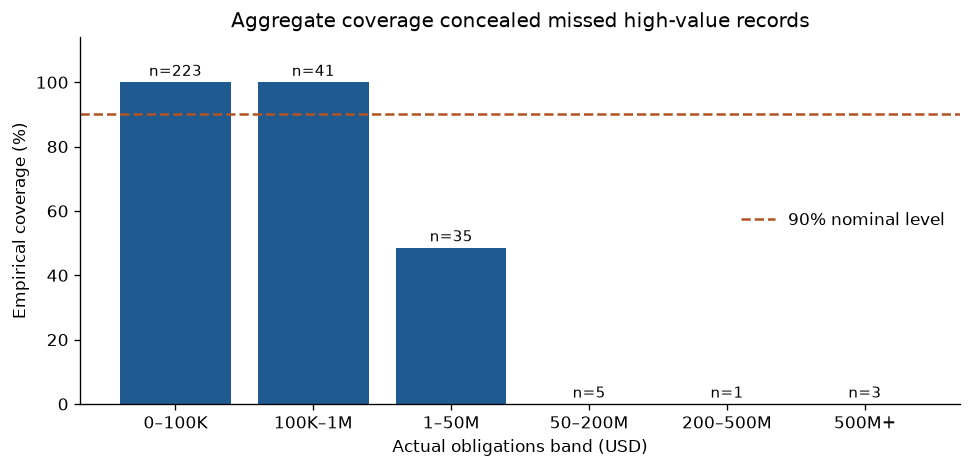

In [8]:
u = load("uncertainty/interval_metrics.csv")
main = u.query("variant == 'nested_metadata' and axis == 'all'")
display(main[["method","level","n","coverage","median_width_usd","mean_width_usd","review_rate"]])
bands = ["0–100K","100K–1M","1–50M","50–200M","200–500M","500M+"]
tail = u.query("variant == 'nested_metadata' and axis == 'actual_band' and method == 'dollar' and level == .9")
x = np.arange(len(bands))
fig, ax = plt.subplots(figsize=(8.2, 4))
ax.bar(x, 100*tail.coverage, color=blue)
for i, row in enumerate(tail.itertuples(index=False)):
    ax.text(i, 100*row.coverage+2, f"n={row.n}", ha="center", fontsize=9)
ax.axhline(90, linestyle="--", color=orange, label="90% nominal level")
ax.set(ylim=(0,114), xticks=x, xticklabels=bands, ylabel="Empirical coverage (%)",
       xlabel="Actual obligations band (USD)", title="Aggregate coverage concealed missed high-value records")
ax.legend(frameon=False, loc="center right")
finish(fig, "prediction_interval_coverage")

### Sensitivity to linked measurements

Stress tests modified only held-out inputs, with training fixed. The scenarios perturb maximum wind by ±10% and county population and mapped fire area by ±20%. These chosen ranges probe response sensitivity and do not estimate a measurement-error distribution.

In [9]:
s = load("uncertainty/measurement_sensitivity_summary.csv")
display(s.round(4))

,scenario,affected_cases,band_change_rate,median_absolute_change_usd,p90_absolute_change_usd,max_absolute_change_usd
0,fire_area_minus_20_percent,1,0.0000,0.0000,0.0000,0.000000e+00
1,fire_area_plus_20_percent,1,0.0000,0.0000,0.0000,0.000000e+00
2,population_minus_20_percent,293,0.0171,0.1139,161.1184,1.036464e+06
3,population_plus_20_percent,293,0.0102,0.1039,131.7696,1.752527e+05
4,wind_minus_10_percent,48,0.0000,0.0000,94025.4214,5.575240e+05
5,wind_plus_10_percent,48,0.0000,0.0000,79522.5334,1.360126e+06


## 6. Allocation under uncertain need and budgets

The policy experiment uses independently simulated service needs across 12 events and three budget waves. Each scenario supplies the same arrivals, demand, and randomly released budgets to all seven candidate policies. Service is capped by realized need when scoring, while the policies depend only on the planning estimates available at an arrival wave. The illustrative result reports trade-offs in need served and service of higher-vulnerability groups.

,policy,need_met,p10_service_fraction,high_vulnerability_service,weighted_wait_units
42,efficient_expected,0.4969,0.1692,0.5272,10616.5230
43,equal,0.4543,0.2429,0.5089,11447.9446
44,equity_expected,0.4959,0.2332,0.6233,10391.9981
45,equity_robust,0.4883,0.1926,0.6522,10423.0841
46,exposure_priority,0.4075,0.0000,0.3667,12193.5762
47,proportional_need,0.4719,0.1617,0.4876,10993.0084
48,severity_priority,0.3991,0.0069,0.4129,12282.3263


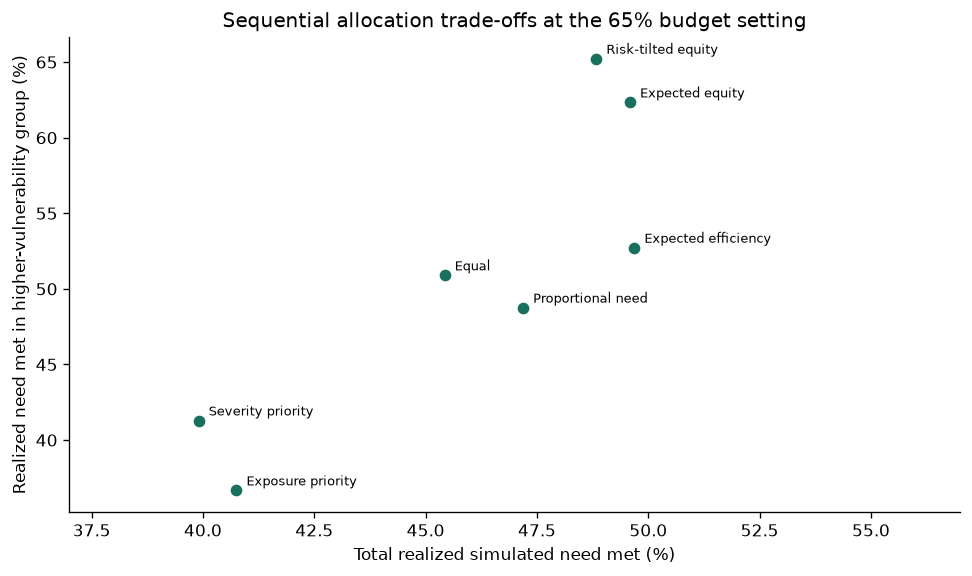

In [10]:
a = load("allocation/synthetic_allocation_metrics.csv")
focus = a.query("planned_budget_ratio == .65 and need_log_noise == .6 and arrival_type == 'sequential'")
display(focus[["policy","need_met","p10_service_fraction","high_vulnerability_service","weighted_wait_units"]].round(4))
fig, ax = plt.subplots(figsize=(8.2, 4.9))
policy_names = {"efficient_expected":"Expected efficiency", "equity_expected":"Expected equity",
                "equity_robust":"Risk-tilted equity", "equal":"Equal", "proportional_need":"Proportional need",
                "exposure_priority":"Exposure priority", "severity_priority":"Severity priority"}
for row in focus.itertuples(index=False):
    ax.scatter(100*row.need_met, 100*row.high_vulnerability_service, color=green)
    ax.annotate(policy_names[row.policy], (100*row.need_met,100*row.high_vulnerability_service),
                xytext=(6, 3), textcoords="offset points", fontsize=8)
ax.set(xlim=(37,57), xlabel="Total realized simulated need met (%)",
       ylabel="Realized need met in higher-vulnerability group (%)",
       title="Sequential allocation trade-offs at the 65% budget setting")
finish(fig, "allocation_tradeoffs")

## 7. Decision briefing

The historical disaster briefing shows observations, source availability, estimates, and review status. The policy section displays a different, synthetic event with estimated need, simulated outcomes and allocation in service units. See the technical guide for raw retrieval, full rebuilding and the command-line demonstration.

In [11]:
brief = json.loads((results/"decision_support_demonstration.json").read_text())
display(brief["historical_disaster"], brief["retrospective_model_estimate"])
display(pd.DataFrame(brief["simulated_humanitarian_allocation"]["policy_comparison"]))

{'id': 4722,
 'hazard': 'Flood',
 'state': 'MN',
 'recorded_dates': {'start': '2023-04-11', 'end': '2023-04-30'},
 'historical_fema_obligations_usd': 1243478.26,
 'evidence_fields_available': ['daymet_point_max_24h_mm',
  'daymet_point_incident_total_mm'],
 'evidence_fields_missing': ['measured_gust_kt',
  'estimated_gust_kt',
  'hail_in',
  'tornado_ef',
  'tornado_length_mi',
  'tornado_width_yd',
  'cyclone_max_wind_kt',
  'cyclone_min_pressure_mb',
  'cyclone_max_34kt_radius_nm',
  'cyclone_landfall_records',
  'mtbs_burned_acres',
  'quake_magnitude',
  'quake_depth_km',
  'quake_shakemap_max_mmi',
  'usgs_discharge_anomaly'],
 'evidence_provenance': 'research/SOURCE_AND_FEATURE_MANIFEST.csv'}

{'historical_obligation_estimate_usd': 5677.770840429999,
 'band': '1M-50M',
 'band_probabilities': {'0-100K': 0.0744928966533713,
  '100K-1M': 0.0027450918417107,
  '1M-50M': 0.9227620115049188,
  '50-200M': 0.0,
  '200-500M': 0.0,
  '500M+': 0.0},
 'intervals': [{'level': 0.8,
   'lower_usd': 0.0,
   'upper_usd': 754245.3430860257},
  {'level': 0.9, 'lower_usd': 0.0, 'upper_usd': 4288908.210935917}],
 'human_review': True,
 'availability_limit': 'later-year retrospective test, exact original decision-time versions unverified'}

,hazard,estimated_need_units,simulated_need_units,allocation_units,vulnerability,policy
0,winter,1090.424008,1144.62129,690.962514,0.437678,equal
1,winter,1090.424008,1144.62129,916.558737,0.437678,proportional_need
2,winter,1090.424008,1144.62129,1690.157213,0.437678,severity_priority
3,winter,1090.424008,1144.62129,0.000000,0.437678,exposure_priority
4,winter,1090.424008,1144.62129,867.428031,0.437678,efficient_expected
5,winter,1090.424008,1144.62129,708.775605,0.437678,equity_expected
6,winter,1090.424008,1144.62129,1090.424008,0.437678,equity_robust


## Conclusion and limitations

Preserve the historical model. The case study establishes uneven measurement coverage, localized cross-sensor flood agreement, and the difficulty of generalizing funding estimates across fiscal years and rare bands. The forward results and allocation simulation support research and human review. Further independent validation requires original decision-time source versions, mature outcome data, event-scale exposure verification and independent service-need labels.

## 8. Rare-obligation augmentation

The 33 configurations use the same 376 real FY2019–24 forward cases. Synthetic features and monetary proxies come from eligible training rows generated separately within each fit. Earlier tuning and calibration used disjoint real episodes. The already examined test years make this an exploratory comparison. The 143 FY2025 declarations stay target-free. [Protocol](augmentation/PROTOCOL.md), [complete results](augmentation/REPORT.md).

In [12]:
from pathlib import Path
import pandas as pd

augmentation = Path("research/augmentation")
if not augmentation.exists():
    augmentation = Path("augmentation")
aug_results = augmentation / "results"
methods = ["real_1x", "nested_weight", "nested_random", "nested_smote", "nested_smotenc",
           "nested_smoter", "nested_smogn", "nested_hybrid", "nested_copula"]
metrics = pd.read_csv(aug_results / "metrics.csv")
summary = metrics.query('probability_scope == "calibrated"').set_index("variant").loc[methods].copy()
for field in ("mae_usd", "rmse_usd", "tail_mae_usd"):
    summary[field.replace("_usd", "_millions_usd")] = summary[field] / 1e6
summary[["accuracy", "balanced_accuracy", "macro_f1", "tail_average_precision", "false_tail_alerts",
         "mae_millions_usd", "rmse_millions_usd", "tail_mae_millions_usd", "r2"]].round(3)

,accuracy,balanced_accuracy,macro_f1,tail_average_precision,false_tail_alerts,mae_millions_usd,rmse_millions_usd,tail_mae_millions_usd,r2
variant,,,,,,,,,
real_1x,0.691,0.213,0.195,0.350,53,19.879,190.344,553.274,-0.007
nested_weight,0.694,0.211,0.189,0.346,52,21.641,182.953,500.604,0.070
nested_random,0.686,0.240,0.233,0.219,43,19.973,187.607,540.606,0.022
nested_smote,0.691,0.213,0.195,0.350,53,19.879,190.344,553.274,-0.007
nested_smotenc,0.702,0.204,0.196,0.245,47,19.879,190.344,553.274,-0.007
nested_smoter,0.702,0.204,0.196,0.231,47,19.885,190.446,553.595,-0.008
nested_smogn,0.697,0.200,0.190,0.298,55,19.880,190.202,552.927,-0.005
nested_hybrid,0.694,0.214,0.196,0.350,52,19.879,190.325,553.259,-0.007
nested_copula,0.691,0.213,0.195,0.350,53,19.879,190.344,553.274,-0.007


In [13]:
episode_deltas = pd.read_csv(aug_results / "paired_episode_bootstrap.csv")
tail_deltas = episode_deltas.query('metric == "tail_mae"').set_index("variant")
coverage = pd.read_csv(aug_results / "intervals.csv")
tail_coverage = coverage.query('subset == "at_least_50m"')
assert tail_coverage.covered.eq(0).all() and tail_coverage.n.eq(13).all()
assert summary.n.eq(376).all()
print("Tail coverage at both nominal levels across all configurations: 0/13")
(tail_deltas[["difference", "p025", "p975"]] / 1e6).round(3).rename(
    columns={"difference": "Tail MAE change ($M)", "p025": "95% lower", "p975": "95% upper"})

Tail coverage at both nominal levels across all configurations: 0/13


,Tail MAE change ($M),95% lower,95% upper
variant,,,
nested_copula,0.000,0.000,0.000
nested_hybrid,-0.014,-0.218,0.184
nested_random,-12.668,-38.455,-0.648
nested_smogn,-0.347,-0.805,0.003
nested_smote,0.000,0.000,0.000
nested_smotenc,0.000,0.000,0.000
nested_smoter,0.322,-0.142,1.208
nested_weight,-52.669,-91.564,-12.346


In [14]:
support = pd.read_csv(aug_results / "support.csv")
outer_support = support[support.fold.str.contains("/outer/")]
print("Maximum compatible $200M–$500M training episodes:",
      outer_support.loc[outer_support.band.eq(4), "max_episodes_per_state_hazard"].max())
print("Strata passing the Gaussian copula gate:", support.state_hazard_strata_copula_gate.sum())
physics = pd.read_csv(aug_results / "physics_impact_pilot.csv")
assert len(physics) == 21 and not physics.eligible_for_obligation_model_training.any()
physics.groupby("scenario_exposed_share").simulated_direct_loss_usd.agg(["min", "max"]).div(1e6).round(2).rename(
    columns={"min": "Minimum direct loss ($M)", "max": "Maximum direct loss ($M)"})

Maximum compatible $200M–$500M training episodes: 1
Strata passing the Gaussian copula gate: 0


,Minimum direct loss ($M),Maximum direct loss ($M)
scenario_exposed_share,,
0.01,28.01,145.37
0.05,140.03,726.87
0.20,560.13,2907.47


The exploratory amount gains from weighting and repeats coexist with tail MAE above $500M and zero tail interval coverage. No synthetic method qualifies for integration. The USACE scenarios estimate direct property losses and leave humanitarian need and FEMA obligations unassigned. Sparse independent high-funding episodes limit both generator fitting and empirical confirmation. [Generator audit](augmentation/GENERATOR_AUDIT.md), [replay guide](augmentation/REPRODUCE.md).

## 9. Historical coverage and physical transfer

A documented publishing boundary separates valid follow-up work on observed obligations from the archived precoverage zeros. The earthquake experiment independently tests synthetic transfer on measured ground shaking. No prediction in these experiments uses a FY2025 obligation. [Coverage study](continuous/coverage/REPORT.md), [auxiliary study](continuous/earthquake/REPORT.md).

In [15]:
from pathlib import Path
import pandas as pd

continuous = Path("research/continuous")
if not continuous.exists():
    continuous = Path("continuous")
coverage = pd.read_csv(continuous / "coverage/ablation/metrics.csv")
pooled = coverage.query('scope == "pooled"').copy()
pooled["tail_mae_millions"] = pooled["mae_50m_usd"] / 1e6
assert pooled.n.eq(376).all()
pooled[["policy", "config", "balanced_accuracy", "ap_50m", "tail_mae_millions", "positive_brier"]].round(4)

,policy,config,balanced_accuracy,ap_50m,tail_mae_millions,positive_brier
0,archive_all,real_1x,0.2084,0.2916,553.2736,0.2292
7,archive_all,weight_20x,0.4003,0.2474,500.6043,0.2292
14,coverage_screened,real_1x,0.2528,0.2821,547.5684,0.2052
21,coverage_screened,weight_20x,0.3804,0.2782,477.7675,0.2052


In [16]:
shaking = pd.read_csv(continuous / "earthquake/results/pga_metrics.csv")
assert shaking.held_episodes.eq(7).all()
shaking[["model", "held_stations", "equal_episode_log_mae", "strong_station_log_mae",
         "reference_stress_band_coverage"]].round(4)

,model,held_stations,equal_episode_log_mae,strong_station_log_mae,reference_stress_band_coverage
0,hybrid_100,143,0.5216,0.6093,0.7832
1,hybrid_1000,143,0.5223,0.6111,0.7762
2,hybrid_500,143,0.5216,0.6103,0.7832
3,hybrid_5000,143,0.5222,0.6110,0.7762
4,physics_intercept_calibrated,143,0.5619,0.6564,0.7972
5,physics_only,143,0.6992,0.4058,0.6923
6,real_only,143,0.5383,0.6319,0.7552


The coverage-aware forward training input policy is retained. The resulting prediction models and the ground-motion synthetic prior remain exploratory. The original Track A and FY2025 reservation are preserved. [Replay guide](continuous/REPRODUCE.md).

## 10. Verified filing times and impact support

Federal Register notices supply a dated publication route for 341 historical declarations. NCEI supplies reported earthquake losses while the USGS archive supplies instrument measurements. Neither source met the support gate for an additional forward prediction model in this batch. [Filing evidence](continuous/filings/REPORT.md), [impact support](continuous/impacts/REPORT.md).

In [17]:
from pathlib import Path
import pandas as pd

continuous = Path("research/continuous")
if not continuous.exists():
    continuous = Path("continuous")
filings = pd.read_csv(continuous / "filings/results/coverage_summary.csv")
availability = filings.pivot(index="horizon_hours", columns="status", values="declarations").fillna(0).astype(int)
assert availability.sum(axis=1).eq(376).all()
assert availability.loc[availability.index <= 168, "covered"].eq(0).all()
availability

status,ambiguous,covered,late,missing,right_censored
horizon_hours,,,,,
0,0,0,341,32,3
24,0,0,341,30,5
48,0,0,341,30,5
72,0,0,341,29,6
168,0,0,341,24,11
336,5,7,329,20,15
720,9,98,234,18,17


In [18]:
impact = pd.read_csv(continuous / "impacts/results/comcat_impact_links.csv")
linked = impact.query('status == "unique_match" and scored_instruments >= 5')
assert linked.damageMillionsDollars.notna().sum() == 4
linked[["episode", "scored_instruments", "damageMillionsDollars", "housesDestroyed", "deaths"]]

,episode,scored_instruments,damageMillionsDollars,housesDestroyed,deaths
1,ci9108652,5.0,NaN,NaN,NaN
6,nc30228270,35.0,NaN,NaN,NaN
8,ci14565620,10.0,NaN,NaN,NaN
9,ci14607652,10.0,1150.0,NaN,2.0
13,nc72282711,403.0,700.0,160.0,1.0
20,ci38457511,25.0,5300.0,101.0,NaN
27,nc73821036,29.0,250.0,150.0,2.0


## 11. Historical outcome maturity and constrained relief delivery

The signed obligation audit separates elapsed outcomes from eventual totals and tracks the effect of a reporting buffer on upper-band training support. The two-day water experiment tests stochastic recourse separately with hypothetical delivery, logistics and need. [Outcome horizons](continuous/horizons/REPORT.md), [water recourse](continuous/water_recourse/REPORT.md).

In [19]:
from pathlib import Path
import pandas as pd

continuous = Path("research/continuous")
if not continuous.exists():
    continuous = Path("continuous")
maturity = pd.read_csv(continuous / "horizons/results/past_only_support.csv")
mature = maturity.query('policy == "elapsed_36m_plus_90d_at_origin"')
mature.pivot(index="held_fy", columns="threshold_usd", values="exceedance_episodes")

threshold_usd,50000000,200000000,500000000
held_fy,,,
2019,1,1,0
2020,1,1,0
2021,2,1,0
2022,8,6,2
2023,12,6,2
2024,12,6,2


In [20]:
water = pd.read_csv(continuous / "water_recourse/results/policy_metrics.csv").set_index("policy")
water.mul(100).round(2)

,service_fraction,vulnerability_weighted_service,high_vulnerability_service,day1_service_fraction,p10_weighted_service
policy,,,,,
myopic_equal_fraction,68.52,68.44,69.94,84.39,41.76
myopic_equity,68.52,70.66,84.50,84.39,42.84
recourse_cvar,67.89,70.48,85.76,80.66,43.73
recourse_expected,68.45,70.69,84.81,83.92,42.84


## 12. Original announcement timing and forecast wind geometry

Archive clocks separate original publication from later edits. Operational hurricane forecast extents are evaluated at later NOAA coastal stations. These physical and availability comparisons do not establish independent obligation performance. [Announcements](continuous/announcements/REPORT.md), [wind evaluation](continuous/winds/REPORT.md).

In [21]:
from pathlib import Path
import pandas as pd

base = Path("research/continuous")
if not base.exists():
    base = Path("continuous")
a = pd.read_csv(base / "announcements/results/availability_summary.csv")
a.query('status == "covered"').pivot(index="hours", columns="clock", values="declarations").fillna(0).astype(int)

clock,archived_modified_utc,archived_published_utc
hours,,
24,77,166
48,88,177
72,91,177
168,91,177
336,91,177
720,91,177


In [22]:
w = pd.read_csv(base / "winds/results/station_contingencies.csv")
w.query('storm == "all"')[["extent", "observed_pairs", "tp", "fp", "fn", "sensitivity", "precision"]]

,extent,observed_pairs,tp,fp,fn,sensitivity,precision
0,quadrant,842,31,148,3,0.911765,0.173184
1,equal_area_circle,842,32,175,2,0.941176,0.154589


## 13. Complete source pagination and the independent wind extension

The complete archived declaration page sequence increases geospatial coverage. Forward scores use the original eligibility criteria, matched cases, and a shared episode purge. The separate wind validation uses six new storms. [Recovered geography](continuous/complete_geography/REPORT.md), [independent wind](continuous/wind_extension/REPORT.md).

In [23]:
from pathlib import Path
import pandas as pd

continuous = Path("research/continuous")
if not continuous.exists():
    continuous = Path("continuous")
g = pd.read_csv(continuous / "complete_geography/results/county_coverage_by_declaration.csv")
assert (g.prior_counties <= g.recovered_counties).all()
columns = ["prior_counties", "recovered_counties"]
g.groupby("incidentType")[columns].sum().sort_values("recovered_counties", ascending=False)

,prior_counties,recovered_counties
incidentType,,
Severe Storm,4095,6122
Flood,1896,2841
Hurricane,1595,2663
Severe Ice Storm,500,823
Snowstorm,429,600
Fire,146,322
Tornado,167,261
Tropical Storm,79,176
Winter Storm,64,101


In [24]:
m = pd.read_csv(continuous / "complete_geography/ablation/metrics.csv")
show = m.query('scope == "all"')[["variant", "accuracy", "balanced_accuracy", "mae_usd", "tail_mae_usd", "tail_ap"]]
show.assign(mae_usd=show.mae_usd.round(), tail_mae_usd=show.tail_mae_usd.round())

,variant,accuracy,balanced_accuracy,mae_usd,tail_mae_usd,tail_ap
0,all_pages_geography,0.582447,0.342525,19680904.0,549865679.0,0.287352
7,all_pages_verified_link_only,0.593085,0.443502,19501707.0,544132453.0,0.406097
14,metadata_reference,0.497340,0.372803,19798617.0,549891923.0,0.377601
21,prior_pages_geography,0.603723,0.315687,19726207.0,550833756.0,0.267064
28,prior_pages_verified_link_only,0.593085,0.321726,19619252.0,547958647.0,0.400582


In [25]:
fields = pd.read_csv(continuous / "announcement_fields/results/forward_joint_support.csv")
assert fields.training_rows_with_field_and_elapsed_label.eq(0).all()
w = pd.read_csv(continuous / "wind_extension/results/station_contingencies.csv")
w.query('storm == "all"')[["extent", "observed_pairs", "tp", "fp", "fn"]]

,extent,observed_pairs,tp,fp,fn
0,quadrant,1704,76,264,12
1,equal_area_circle,1704,78,264,10


The framework uses the complete page version for separately registered retrospective analyses. Both legacy evidence and the FY2025 holdout are preserved. The matched results provide no operational prediction promotion, and the wind extension leaves a consistent contour advantage unresolved. [Replay guide](continuous/REPRODUCE.md).

## 14. Earlier announcement versions and reported electricity disturbance duration

The earlier documentary pilot matches historical declaration identities to original-site snapshots. It ties exact bodies to independent capture times and then checks training support against the elapsed funding-label gate. The separate DOE analysis compares empirical and synthetic duration distributions on real held reports. [Documentary report](continuous/older_announcements/REPORT.md), [disturbance report](continuous/disturbance_duration/REPORT.md).

In [26]:
from pathlib import Path
import pandas as pd

continuous = Path("research/continuous")
if not continuous.exists():
    continuous = Path("continuous")

versions = pd.read_csv(continuous / "older_announcements/results/capture_versions.csv")
verified = versions[versions.content_identity_verified]
earliest = verified.sort_values("capture_utc").drop_duplicates("disasterNumber")
assert len(earliest) == 6 and (~earliest.same_body_as_nara).sum() == 2

support = pd.read_csv(continuous / "older_announcements/results/mature_support.csv")
support.query("horizon_hours == 72")[[
    "held_fy",
    "mature_eligible_population_ceiling",
    "mature_sample_claim_upper_bound",
    "mature_sample_verified_lower_bound",
]]

,held_fy,mature_eligible_population_ceiling,mature_sample_claim_upper_bound,mature_sample_verified_lower_bound
3,2019,0,0,0
10,2020,0,0,0
17,2021,9,2,0
24,2022,43,7,2
31,2023,80,12,4
38,2024,106,16,4


In [27]:
duration = continuous / "disturbance_duration/results"
scores = pd.read_csv(duration / "scores.csv").query('population == "all"').set_index("model")
brier_gain = 1 - scores.loc["hybrid_half_synthetic", "brier_24h"] / scores.loc["empirical_seasonal", "brier_24h"]
assert 0 < brier_gain < 0.05
scores[["n", "brier_24h", "log_pinball_90", "covered_90", "median_upper_90_hours"]].round(4)

,n,brier_24h,log_pinball_90,covered_90,median_upper_90_hours
model,,,,,
empirical_pooled,172,0.2516,0.1739,0.9128,76.2667
empirical_seasonal,172,0.2513,0.1821,0.9012,74.1500
hybrid_half_synthetic,172,0.2473,0.1810,0.9070,85.7833
seasonal_synthetic_prior,172,0.2439,0.1794,0.9244,88.9011


In [28]:
summary = pd.read_csv(duration / "duration_summary.csv")
summary[["archive_year", "criteria_selected_in_scope", "usable_duration", "missing_endpoint"]]

,archive_year,criteria_selected_in_scope,usable_duration,missing_endpoint
0,2018,78,64,14
1,2019,75,67,8
2,2020,122,99,23
3,2021,81,63,18
4,2022,73,56,17
5,2023,67,41,15
6,2024,92,12,80


Early content and mature funding overlap for at most four verified prior cases. The DOE mixture clears the paired statistical screen and misses the practical gain threshold. Based on this evidence, both approaches remain exploratory. [Locked protocol](continuous/BATCH6_PROTOCOL.md), [offline replay](continuous/REPRODUCE.md).

## 15. Documentary forward support and county outage observability

The extended archive directly verifies additional early document bodies. The model feasibility screen counts groups jointly eligible for historical outcome maturity and document timing at each origin. The separate county outage audit verifies quarter-hour observation windows and compares different threshold endpoints. [Documentary support](continuous/documentary_extension/REPORT.md), [outage endpoints](continuous/county_outages/REPORT.md).

In [29]:
from pathlib import Path
import pandas as pd

continuous = Path("research/continuous")
if not continuous.exists():
    continuous = Path("continuous")

documentary = continuous / "documentary_extension/results"
versions = pd.read_csv(documentary / "capture_versions.csv")
assert versions.loc[versions.content_identity_verified, "disasterNumber"].nunique() == 31
origins = pd.read_csv(documentary / "documentary_support_by_origin.csv")
table = origins.query('horizon_hours == 72 and evidence_tier == "combined_distinct_evidence_tiers"')
assert table.prior_groups.max() == 17 and table.held_groups.max() == 12
table[["held_fy", "prior_groups", "held_groups", "prior_groups_ge_50m", "held_groups_ge_50m"]]

,held_fy,prior_groups,held_groups,prior_groups_ge_50m,held_groups_ge_50m
14,2019,0,6,0,1
30,2020,0,4,0,0
46,2021,0,12,0,1
62,2022,5,12,1,2
78,2023,9,7,2,1
94,2024,17,0,2,0


In [30]:
gates = pd.read_csv(documentary / "documentary_gate_summary.csv")
assert not gates.rare_gate_met.any()
gates.query("horizon_hours == 72")[["evidence_tier", "general_eligible_origins", "rare_eligible_origins"]]

,evidence_tier,general_eligible_origins,rare_eligible_origins
3,archived_edit_metadata_2021_2024,0,0
7,combined_distinct_evidence_tiers,0,0
11,exact_captures_2017_2020,0,0
15,maturity_only_ceiling,5,0


In [31]:
outage = continuous / "county_outages/results"
windows = pd.read_csv(outage / "county_window_summary.csv")
aggregate = windows.query('geography == "all_counties"')
assert aggregate.complete_24h_windows.item() == 3471
aggregate[["verified_threshold_entries", "complete_24h_windows",
           "confirmed_below_by_24h_in_complete_windows", "confirmed_below_at_24h_in_complete_windows",
           "complete_windows_with_reentry_after_drop"]]

,verified_threshold_entries,complete_24h_windows,confirmed_below_by_24h_in_complete_windows,confirmed_below_at_24h_in_complete_windows,complete_windows_with_reentry_after_drop
0,5513,3471,3447,2771,2713


The chronology and elapsed labels leave an insufficient number of rare groups for the proposed forecasting comparison. County outages require explicit observation coverage and a fixed definition of what constitutes a drop below the threshold. The first observed drop and a below-threshold state at 24 hours have different support. [Frozen protocol and endpoints](continuous/BATCH7_PROTOCOL.md), [replay guide](continuous/REPRODUCE.md).

## 16. Earlier federal accounting evidence and sustained county outage recovery

The precoverage documentary audit verifies published historical sources and checks their eligibility as elapsed Mission Assignment labels. The separate outage trial holds out two later calendar years and compares real-only learning to weighted simulations of observed county threshold trajectories. [Federal documentary evidence](continuous/precoverage_documentary/REPORT.md), [sustained outage trial](continuous/sustained_outage/REPORT.md).

In [32]:
from pathlib import Path
import pandas as pd

continuous = Path("research/continuous")
if not continuous.exists():
    continuous = Path("continuous")

documents = continuous / "precoverage_documentary/results"
gate = pd.read_csv(documents / "gate_summary.csv").iloc[0]
assert gate.verified_passages == 18 and gate.eligible_36_month_labels == 0
revisions = pd.read_csv(documents / "dod_revisions.csv")
revisions[["source_as_of_date", "nominal_usd", "change_from_first_usd"]]

,source_as_of_date,nominal_usd,change_from_first_usd
0,2005-09-28,2200000000,0
1,2005-11-03,1700000000,-500000000
2,2006-03-15,1100000000,-1100000000


In [33]:
sustained = continuous / "sustained_outage"
metrics = pd.read_csv(sustained / "results/scores.csv")
assert metrics.query('population == "all_held"').rows.eq(2139).all()
metrics.pivot(index="population", columns="model", values="brier").round(6)

model,hybrid_logistic,pooled_prevalence,real_logistic
population,,,
2022,0.187751,0.198031,0.187911
2023,0.185363,0.195929,0.184759
all_held,0.186610,0.197027,0.186405


In [34]:
primary = pd.read_csv(sustained / "results/paired_brier_intervals.csv").assign(analysis="primary")
sensitivity = pd.read_csv(sustained / "zero_sensitivity/paired_brier_intervals.csv").assign(analysis="explicit zeros excluded")
paired = pd.concat([primary, sensitivity], ignore_index=True)
assert (paired.paired_95_lower.lt(0) & paired.paired_95_upper.gt(0)).all()
paired[["analysis", "block_days", "held_blocks", "hybrid_minus_real_brier", "paired_95_lower", "paired_95_upper"]].round(6)

,analysis,block_days,held_blocks,hybrid_minus_real_brier,paired_95_lower,paired_95_upper
0,primary,14,52,0.000205,-0.000622,0.001009
1,primary,28,26,0.000205,-0.000620,0.000990
2,explicit zeros excluded,14,52,0.000353,-0.000481,0.001188
3,explicit zeros excluded,28,26,0.000353,-0.000499,0.001189


The federal records demonstrate why a signed action sequence and a fixed elapsed cutoff are required. The outage comparison supports the real-only model as a research baseline. The synthetic trajectories did not clear the integration gate. [Design and endpoints](continuous/BATCH8_PROTOCOL.md), [offline replay](continuous/REPRODUCE.md).

## 17. Component accounting and forecast exposure support

Recipient-side audits identify individual historical assignments and distinguish authority, billing and closure. The separate wind linkage measures the support for a jointly observed weather and sustained outage population. [Component audit](continuous/component_accounting/REPORT.md), [wind linkage](continuous/county_wind_exposure/REPORT.md).

In [35]:
from pathlib import Path
import pandas as pd

continuous = Path("research/continuous")
if not continuous.exists():
    continuous = Path("continuous")

component = continuous / "component_accounting/results"
summary = pd.read_csv(component / "gate_summary.csv").iloc[0]
assert summary.exact_assignment_keys == 2 and summary.eligible_elapsed_declaration_labels == 0
keys = pd.read_csv(component / "exact_assignment_keys.csv")
keys[["dr_id", "state", "exact_assignment_key", "stage", "usd"]]

,dr_id,state,exact_assignment_key,stage,usd
0,1604,MS,1604DRMSNCS0900,closure_directive,100000
1,1603,LA,1603DRLANCS0600,assignment_plus_amendments,1600000


In [36]:
outages = pd.read_csv(continuous / "county_wind_exposure/results/storm_support.csv")
regional = outages.query('state == "all" and stratum == "within_400km"')
assert regional.complete.sum() == 7
assert ((regional.sustained_below > 0) & (regional.not_sustained_below > 0)).sum() == 1
regional[["storm", "rows", "complete", "sustained_below", "not_sustained_below", "complete_and_quadrant_inside"]]

,storm,rows,complete,sustained_below,not_sustained_below,complete_and_quadrant_inside
1,michael_2018,3,2,0,2,1
14,laura_2020,1,1,0,1,0
26,ian_2022,3,3,2,1,2
38,idalia_2023,1,1,1,0,0


Exact recipient-side references preserve a route to original records. The finance gate requires a complete signed declaration history. The wind feasibility gate requires additional independent storms and systematically sampled counties in the forecast footprint. [Reproduction guide](continuous/REPRODUCE.md).

## 18. Legacy ledger witnesses, selected storm geography, and measured need

The public ledger audit applies exact historic identifiers and preserves missing precoverage outcomes. The hurricane panel was committed before the expanded outage rows were selected. Separately published survey measurements describe humanitarian need and receipt on their own populations. [Protocol](continuous/BATCH10_PROTOCOL.md), [backlog](continuous/BACKLOG.md).

In [37]:
from pathlib import Path
import pandas as pd

continuous = Path("research/continuous")
if not continuous.exists():
    continuous = Path("continuous")

legacy = continuous / "legacy_ledger_gate/results"
ledger = pd.read_csv(legacy / "gate_summary.csv")
assert ledger.eligible_new_elapsed_labels.item() == 0
ledger[["legacy_declarations_checked", "legacy_actions", "control_actions", "control_negative_actions"]]

,legacy_declarations_checked,legacy_actions,control_actions,control_negative_actions
0,5,0,1548.0,645.0


In [38]:
storm = continuous / "storm_outage_panel"
primary = pd.read_csv(storm / "results/gate_summary.csv").assign(analysis="recorded counts")
sensitivity = pd.read_csv(storm / "zero_sensitivity/gate_summary.csv").assign(analysis="zeros excluded")
gates = pd.concat([primary, sensitivity], ignore_index=True)
matched = pd.read_csv(storm / "results/storm_support.csv")
assert matched.complete_regional.sum() == 330
assert not gates.loc[gates.population.eq("new_storms"), "gate_pass"].any()
gates[["analysis", "population", "qualifying_prior_storms", "qualifying_held_storms", "gate_pass"]]

,analysis,population,qualifying_prior_storms,qualifying_held_storms,gate_pass
0,recorded counts,all_storms,7,3,True
1,recorded counts,new_storms,5,1,False
2,zeros excluded,all_storms,7,2,True
3,zeros excluded,new_storms,5,0,False


In [39]:
humanitarian = continuous / "humanitarian_source/results"
hps = pd.read_csv(humanitarian / "hps_summary.csv")
assert set(hps.week) == {52, 61, 62}
hps.query('region == "US"')[["week", "displaced_any_prior_year", "displaced_hurricane_prior_year",
                            "food_shortage_share_of_displaced", "water_shortage_share_of_displaced"]].round(3)

,week,displaced_any_prior_year,displaced_hurricane_prior_year,food_shortage_share_of_displaced,water_shortage_share_of_displaced
44,52,3333947.0,1927340.0,0.191,0.153
96,61,2769611.0,1299240.0,0.182,0.126
148,62,2864135.0,1048381.0,0.170,0.167


In [40]:
casper = pd.read_csv(humanitarian / "casper_published_estimates.csv")
casper[["phase", "measure", "percent", "ci95_low", "ci95_high"]]

,phase,measure,percent,ci95_low,ci95_high
0,2017-11 response,current_food_need,21.0,15.7,26.2
1,2018-02 recovery,current_food_need,11.1,5.7,16.5
2,2017-11 response,current_water_need,23.2,17.6,28.9
3,2018-02 recovery,current_water_need,10.9,6.4,15.5
4,2017-11 response,utility_electricity_available,25.5,16.9,34.1
5,2018-02 recovery,utility_electricity_available,96.7,93.6,99.7
6,2018-02 recovery,received_behavioral_health_services,7.7,3.1,12.3
7,2018-02 recovery,could_not_obtain_needed_behavioral_health_serv...,4.3,0.3,8.3
8,2018-02 recovery,no_behavioral_health_services_needed,88.0,81.1,94.9


The eligibility screens preserve the separation of signed funding outcomes, physical forecasts, reported outage recovery, survey need and service receipt. The independent storm comparison and causal allocation evidence require additional measured support. [Historical ledger](continuous/legacy_ledger_gate/REPORT.md), [storm panel](continuous/storm_outage_panel/REPORT.md), [humanitarian sources](continuous/humanitarian_source/REPORT.md).

The exact year, county and onset join counts eight complete regional windows shared with Batch 8, including one for Nicole. [Overlap table](continuous/storm_outage_panel/results/batch8_endpoint_overlap.csv).

## 19. Coverage-aware estimation and essential-service decisions

The same-origin experiments score an eventual workbook proxy and a 36-month signed endpoint on their respective historical populations. The allocation experiment uses synthetic requests based on aggregate survey summaries and measures simulated service under alternative geographic priorities. [Protocol](continuous/BATCH11_PROTOCOL.md).

In [41]:
from pathlib import Path
import pandas as pd

continuous = Path('research/continuous')
if not continuous.exists():
    continuous = Path('continuous')
coverage = continuous / 'coverage_specialists/results'
observations = pd.read_csv(coverage / 'label_observability.csv')
assert len(observations) == 912 and observations.fyDeclared.max() == 2024
observations.observation_status.value_counts().rename('declarations').to_frame()

,declarations
observation_status,
in_scope_no_public_actions,313
signed_elapsed_positive,297
precoverage_unavailable,223
horizon_pending,51
signed_elapsed_net_zero,27
unusable_action_dates,1


In [42]:
scores = pd.read_csv(coverage / 'scores.csv')
summary = scores.query('population == "pooled"').copy()
summary[['mae', 'tail_mae']] /= 1e6
summary[['endpoint','arm','n','tail_groups','mae','tail_mae','tail_ap','alerts_false_10pct']].round(3)

,endpoint,arm,n,tail_groups,mae,tail_mae,tail_ap,alerts_false_10pct
0,eventual_proxy,hazard_gate_10,376,11,22.846,483.552,0.384,24
7,eventual_proxy,hazard_gate_20,376,11,21.945,503.089,0.384,24
14,eventual_proxy,nested_selected,376,11,21.239,513.506,0.282,49
21,eventual_proxy,positive_hurdle,376,11,19.956,545.735,0.282,37
28,eventual_proxy,real_only,376,11,19.923,547.568,0.282,37
35,eventual_proxy,weighted_20x,376,11,22.288,477.768,0.278,71
42,signed_elapsed,hazard_gate_10,135,10,29.353,310.800,0.687,7
48,signed_elapsed,hazard_gate_20,135,10,29.189,326.188,0.687,7
54,signed_elapsed,nested_selected,135,10,29.764,345.845,0.509,19
60,signed_elapsed,positive_hurdle,135,10,30.017,349.660,0.671,13


In [43]:
paired = pd.read_csv(coverage / 'paired_changes.csv')
subset = paired.query('arm == "nested_selected"').copy()
subset[['change','lower_95','upper_95']] /= 1e6
subset[['endpoint','metric','change','lower_95','upper_95']].round(2)

,endpoint,metric,change,lower_95,upper_95
4,eventual_proxy,mae,1.32,-0.62,3.15
5,eventual_proxy,tail_mae,-34.06,-80.36,-0.00
14,signed_elapsed,mae,-0.08,-1.72,1.33
15,signed_elapsed,tail_mae,-1.81,-22.60,15.78


In [44]:
scenarios = continuous / 'service_scenarios/results'
sources = pd.read_csv(continuous / 'new_humanitarian_evidence/results/measurement_crosswalk.csv')
seeds = pd.read_csv(scenarios / 'scenario_registry.csv')
assert len(seeds) == 192 and not set(seeds.held_seed) & set(seeds.planning_seed)
policy = pd.read_csv(scenarios / 'paired_changes.csv').query('phase == "pooled"').copy()
policy[['paired_difference','lower_95','upper_95']] *= 100
policy[['policy','metric','paired_difference','lower_95','upper_95']].round(2)

,policy,metric,paired_difference,lower_95,upper_95
0,vulnerability_myopic,served_fraction,0.00,-0.00,0.00
1,vulnerability_myopic,high_vulnerability_served_fraction,26.96,25.19,28.62
2,vulnerability_myopic,lowest_zone_fraction,-39.44,-40.92,-37.89
3,expected_recourse,served_fraction,-0.12,-0.17,-0.08
4,expected_recourse,high_vulnerability_served_fraction,27.49,25.64,29.21
5,expected_recourse,lowest_zone_fraction,-46.19,-47.96,-44.32
6,cvar_recourse,served_fraction,-0.30,-0.40,-0.22
7,cvar_recourse,high_vulnerability_served_fraction,27.55,25.68,29.27
8,cvar_recourse,lowest_zone_fraction,-46.73,-48.41,-44.92


Dollar changes are in millions, and simulated coverage changes are in percentage points. The nested signed-endpoint estimate remains uncertain. The service experiment preserves a trade-off between targeted coverage and the minimum zone coverage. The separate observational crosswalk does not establish policy exposure or fulfillment effects. [Funding](continuous/coverage_specialists/REPORT.md), [service simulation](continuous/service_scenarios/REPORT.md), [observed endpoints](continuous/new_humanitarian_evidence/REPORT.md).

## 20. Historic coastal levels and a geographic service floor

Coastal pairs compare verified water levels to harmonic tide predictions in the same local datum. The allocation replay measures paired differences under a fixed geographic minimum. [Frozen protocol](continuous/BATCH12_PROTOCOL.md).

In [45]:
from pathlib import Path
import pandas as pd

continuous = Path('research/continuous')
if not continuous.exists():
    continuous = Path('continuous')
tide = continuous / 'tidal_residual'
gates = pd.concat([pd.read_csv(tide / 'results/storm_gate.csv').assign(analysis='verified product'),
                   pd.read_csv(tide / 'unflagged/storm_gate.csv').assign(analysis='unflagged')])
assert gates.groupby('analysis').qualifies.sum().eq(5).all()
gates.groupby('analysis')[['matched_hours', 'qualifies']].sum()

,matched_hours,qualifies
analysis,,
unflagged,937,5
verified product,954,5


In [46]:
diagnostics = pd.read_csv(tide / 'results/storm_diagnostics.csv')
diagnostics.groupby('hours').agg(
    timestamp_pairs=('timestamp_pairs','sum'),
    tide_only_storm_average_mae_m=('tide_only_mae_m','mean'),
    persistence_storm_average_mae_m=('persistence_mae_m','mean'),
).round(3)

,timestamp_pairs,tide_only_storm_average_mae_m,persistence_storm_average_mae_m
hours,,,
1,852,0.577,0.076
6,792,0.601,0.324


In [47]:
floors = continuous / 'service_floors/results'
seeds = pd.read_csv(floors / 'scenario_registry.csv')
assert len(seeds) == 192 and not set(seeds.held_seed) & set(seeds.planning_seed)
contrasts = pd.read_csv(floors / 'paired_floors.csv').query('nominal_supply == "pooled"').copy()
contrasts[['paired_difference','lower_95','upper_95']] *= 100
contrasts[['policy','metric','paired_difference','lower_95','upper_95']].round(2)

,policy,metric,paired_difference,lower_95,upper_95
0,myopic,served_fraction,0.00,-0.00,0.00
1,myopic,high_vulnerability_served_fraction,-10.17,-11.32,-9.00
2,myopic,lowest_zone_fraction,31.36,29.79,32.97
3,expected,served_fraction,0.03,0.01,0.06
4,expected,high_vulnerability_served_fraction,-10.16,-11.31,-8.98
5,expected,lowest_zone_fraction,31.45,29.88,33.05
6,cvar,served_fraction,0.08,0.04,0.14
7,cvar,high_vulnerability_served_fraction,-10.24,-11.39,-9.05
8,cvar,lowest_zone_fraction,31.57,30.03,33.14


The coastal panel misses the minimum independent storm support for physical transfer. A geographic floor shifts simulated coverage toward the least-served zones. Percent-point changes describe this synthetic policy comparison. [Coastal report](continuous/tidal_residual/REPORT.md), [minimum service report](continuous/service_floors/REPORT.md).

## 21. Fixed catastrophic weighting and coastal physical transfer

The fixed weighting arm remains an exploratory signed-obligation candidate. An entirely separate evaluation compares pressure, station forecasts and an idealized synthetic prior for measured coastal levels. [Funding robustness](continuous/weight_influence/REPORT.md) · [Coastal transfer](continuous/coastal_transfer/REPORT.md)

In [48]:
from pathlib import Path
import pandas as pd

continuous = Path('research/continuous')
if not continuous.exists():
    continuous = Path('continuous')
fund = continuous / 'weight_influence/results'
influence = pd.read_csv(fund / 'paired_differences.csv').set_index('rank') / 1e6
assert (influence.tail_mae < 0).all()
influence.round(2)

,mae,tail_mae,episode_mae,episode_tail_mae
rank,,,,
0,-1.89,-55.86,-1.40,-55.88
1,0.45,-21.62,0.51,-23.78
2,-3.15,-54.27,-2.96,-54.13
3,-3.88,-63.78,-3.66,-64.59


In [49]:
coast = continuous / 'coastal_transfer/results'
storm_gate = pd.read_csv(coast / 'verified/storm_gate.csv')
assert storm_gate.groupby('partition').qualifies.sum().to_dict() == {'earlier': 8, 'held': 4}
coastal_metrics = []
for version in ('verified', 'unflagged'):
    table = pd.read_csv(coast / version / 'storm_scores.csv').assign(version=version)
    coastal_metrics.append(table)
pd.concat(coastal_metrics).pivot_table(index=['version','lead'], columns='arm', values='mae_m').round(4)

arm             hybrid  hydrostatic  persistence  statistical  synthetic_only  \
version   lead                                                                  
unflagged 1     0.0488       0.0636       0.0514       0.0486          0.0660   
          6     0.1819       0.2280       0.1669       0.1791          0.2243   
verified  1     0.0537       0.0701       0.0597       0.0536          0.0723   
          6     0.2229       0.2608       0.2251       0.2212          0.2570   

arm             tide_only  
version   lead             
unflagged 1        0.4158  
          6        0.4368  
verified  1        0.4605  
          6        0.4761

Rank zero retains the full historical funding fit. Higher omission ranks leave an earlier tail episode out of each eligible fit. Paired differences are in millions of dollars. Coastal errors are in meters and each held storm contributes equal weight. The physical arms use no funding observations and draw no operational conclusion.

## 22. Logistics constraints and simulated allocation trade-offs

Prespecified network options vary service floors and objective weights. The graphical frontier compares the average results of the specified alternatives. The demand anchors come from weighted aggregate survey results and the logistics parameters are assumed. [Allocation study](continuous/transport_pareto/REPORT.md) · [Framework interfaces](FRAMEWORK.md)

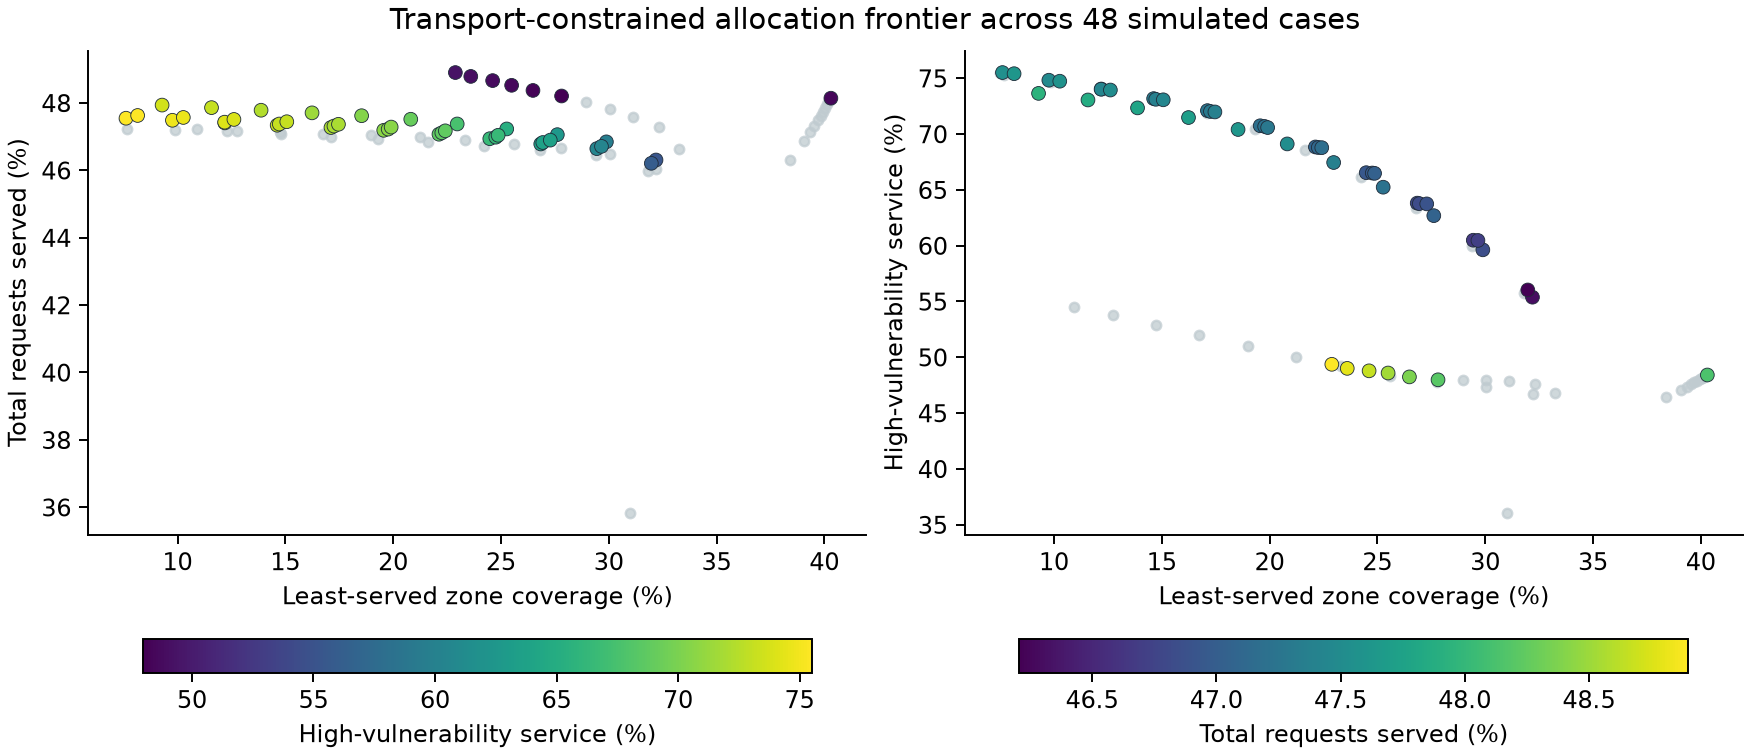

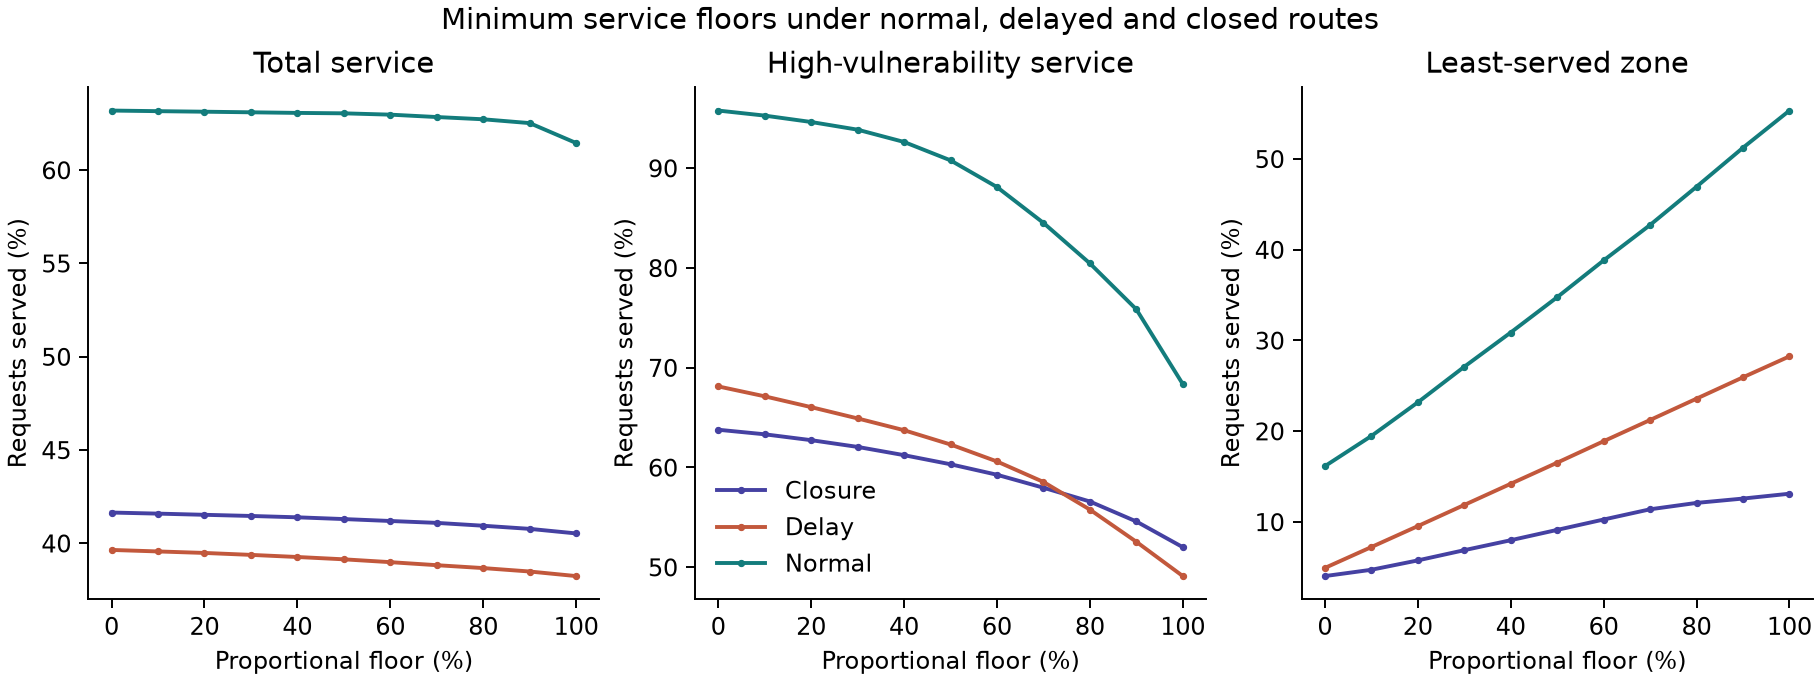

,preference,policy,floor,overall,high_vulnerability,least_served
0,total service,efficiency,0.0,48.90,49.36,22.89
1,vulnerability priority,vulnerability,0.0,47.63,75.40,8.15
2,minimum coverage priority,maxmin,0.0,48.14,48.41,40.30
3,balanced,vulnerability,60.0,47.17,68.77,22.42


In [50]:
from IPython.display import Image, display

alloc = continuous / 'transport_pareto/results'
pareto = pd.read_csv(alloc / 'pareto_points.csv')
register = pd.read_csv(alloc / 'scenario_registry.csv')
assert len(pareto) == 89 and len(register) == 48
display(Image(filename=str(alloc / 'pareto_frontiers.png'), width=850))
display(Image(filename=str(alloc / 'floor_sensitivity.png'), width=850))
choices = pd.read_csv(alloc / 'preference_choices.csv')
cols = ['floor','overall','high_vulnerability','least_served']
choices[cols] *= 100
choices[['preference','policy',*cols]].round(2)